# Rice Disease Classification using EfficientNetV2S

**CropGuard AI: AI-Powered Crop Disease Detection and Advisory System**

Final Year Project, The Islamia University of Bahawalpur (IUB)

| | |
|---|---|
| Students | Muhammad Ali Ejaz, Ahmad Siddique |
| Supervisor | Dr. Faheem Mushtaq |
| Notebook | Rice model (one of six crop models: wheat, rice, cotton, sugarcane, potato, corn) |

## Overview

This notebook trains the rice disease classifier used in CropGuard AI. The model takes a photo of a rice leaf and predicts one of 6 classes (5 diseases plus healthy).

- **Dataset:** Rice Disease Dataset from Kaggle (`afzaalsattar/rice-disease-dataset`). It already comes with separate train, valid and test folders, and these original splits are kept.
- **Model:** EfficientNetV2S pre-trained on ImageNet, with a small classification head on top.
- **Training:** three phases with progressive unfreezing. The base model is frozen first, then unfrozen and trained with smaller learning rates.
- **Evaluation:** accuracy, per-class precision/recall/F1, confusion matrix and sample predictions on the validation set, and a final check on the separate test set.
- **Output:** the trained model and class files that are used by the CropGuard AI backend.

The notebook was run on Kaggle with a GPU.

## 1. Setup

### 1.1 Libraries

In [1]:
import os
import json
import shutil
import zipfile

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetV2S
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)
print("GPUs available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


### 1.2 Configuration

All paths and main settings are kept in one place so they are easy to change.

In [2]:
# Paths
RICE_INPUT = "/kaggle/input/datasets/muhammadafzaalml/rice-diseases-dataset"
RICE_CLEAN = "/kaggle/working/rice_clean"      # cleaned copy of the dataset
OUTPUT_DIR = "/kaggle/working"

TRAIN_DIR = os.path.join(RICE_CLEAN, "train")
VAL_DIR = os.path.join(RICE_CLEAN, "valid")
TEST_DIR = os.path.join(RICE_CLEAN, "test")

# Data settings
IMG_SIZE = (384, 384)
BATCH_SIZE = 16          # safe for EfficientNetV2S at 384 px
SEED = 42
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")

tf.keras.utils.set_random_seed(SEED)

## 2. Dataset Preparation

Before training, the dataset is copied to the working directory (the Kaggle input folder is read-only) and every image is checked. Images that cannot be decoded are removed.

In [3]:
# Copy each split to a writable location
os.makedirs(RICE_CLEAN, exist_ok=True)

for split in ["train", "valid", "test"]:
    src = os.path.join(RICE_INPUT, split)
    dst = os.path.join(RICE_CLEAN, split)
    if os.path.exists(dst):
        print(f"{split}/ already copied, skipping")
        continue
    if not os.path.exists(src):
        print(f"{split}/ not found at {src}")
        continue
    print(f"Copying {split}/ ...")
    shutil.copytree(src, dst)

Copying train/ ...
Copying valid/ ...
Copying test/ ...


In [4]:
# Remove corrupt images (files that TensorFlow cannot decode)
def remove_corrupt_images(root):
    removed = 0
    for cls in os.listdir(root):
        cls_dir = os.path.join(root, cls)
        if not os.path.isdir(cls_dir):
            continue
        for fname in os.listdir(cls_dir):
            fpath = os.path.join(cls_dir, fname)
            try:
                tf.image.decode_image(tf.io.read_file(fpath))
            except Exception:
                os.remove(fpath)
                removed += 1
    return removed


for split in ["train", "valid", "test"]:
    removed = remove_corrupt_images(os.path.join(RICE_CLEAN, split))
    print(f"{split}/: removed {removed} corrupt files")

I0000 00:00:1793081038.202902      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793081038.211874      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


train/: removed 0 corrupt files
valid/: removed 0 corrupt files
test/: removed 0 corrupt files


### 2.1 Class distribution

train/  total = 7965
   Bacterial Leaf Blight: 1335
   Brown Spot: 1317
   Healthy Rice Leaf: 1362
   Leaf Blast: 1317
   Leaf scald: 1284
   Sheath Blight: 1350
valid/  total = 763
   Bacterial Leaf Blight: 144
   Brown Spot: 133
   Healthy Rice Leaf: 130
   Leaf Blast: 113
   Leaf scald: 127
   Sheath Blight: 116
test/  total = 380
   Bacterial Leaf Blight: 47
   Brown Spot: 65
   Healthy Rice Leaf: 66
   Leaf Blast: 67
   Leaf scald: 73
   Sheath Blight: 62


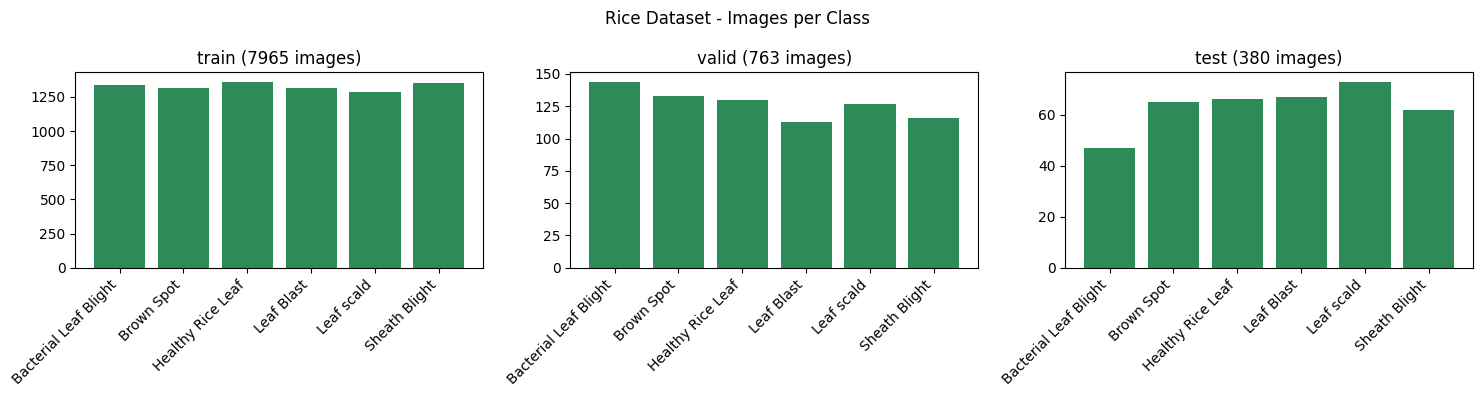

In [5]:
def count_images(folder):
    return len([f for f in os.listdir(folder) if f.lower().endswith(IMAGE_EXTENSIONS)])


split_dirs = {"train": TRAIN_DIR, "valid": VAL_DIR, "test": TEST_DIR}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (split, split_dir) in zip(axes, split_dirs.items()):
    counts = {cls: count_images(os.path.join(split_dir, cls))
              for cls in sorted(os.listdir(split_dir))
              if os.path.isdir(os.path.join(split_dir, cls))}
    print(f"{split}/  total = {sum(counts.values())}")
    for cls, n in counts.items():
        print(f"   {cls}: {n}")
    ax.bar(counts.keys(), counts.values(), color="seagreen")
    ax.set_title(f"{split} ({sum(counts.values())} images)")
    ax.tick_params(axis="x", rotation=45)
    for label in ax.get_xticklabels():
        label.set_ha("right")

plt.suptitle("Rice Dataset - Images per Class")
plt.tight_layout()
plt.show()

The training split is already augmented by the dataset creator, so its classes are almost perfectly balanced. The valid and test splits are much smaller and not balanced.

## 3. Loading the Data

The original train and valid folders are used directly, so there is no random re-splitting. The class names are read from the folder names.

In [6]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", seed=SEED
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

Found 7965 files belonging to 6 classes.
Found 763 files belonging to 6 classes.
Classes: ['Bacterial Leaf Blight', 'Brown Spot', 'Healthy Rice Leaf', 'Leaf Blast', 'Leaf scald', 'Sheath Blight']
Number of classes: 6


## 4. Class Weights

Class weights are calculated from the training folder. Since the training classes are nearly balanced, all the weights should be close to 1.

In [7]:
labels_flat = []
for i, cls in enumerate(class_names):
    labels_flat.extend([i] * count_images(os.path.join(TRAIN_DIR, cls)))
labels_flat = np.array(labels_flat)

cw_values = compute_class_weight("balanced", classes=np.unique(labels_flat), y=labels_flat)
class_weight_dict = {i: w for i, w in enumerate(cw_values)}

for i, cls in enumerate(class_names):
    print(f"{cls}: {class_weight_dict[i]:.3f}")

Bacterial Leaf Blight: 0.994
Brown Spot: 1.008
Healthy Rice Leaf: 0.975
Leaf Blast: 1.008
Leaf scald: 1.034
Sheath Blight: 0.983


## 5. Preprocessing

No extra augmentation is added during training, because the training images are already augmented in the dataset. The images are only passed through the EfficientNetV2S preprocessing function.

In [8]:
def prep(img, lbl):
    return preprocess_input(img), lbl


train_ds_p = train_ds.map(prep, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
val_ds_p = val_ds.map(prep, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

## 6. Model

EfficientNetV2S is used as the base model with ImageNet weights and without its original top layer. On top of it we add:

- Global average pooling to turn the feature maps into one vector
- Batch normalization
- Dropout (0.4) to reduce overfitting
- A dense softmax layer with one output per class

The base model starts frozen so that only the new head is trained in the first phase.

In [9]:
base = EfficientNetV2S(include_top=False, weights="imagenet", input_shape=(384, 384, 3))
base.trainable = False

inputs = keras.Input(shape=(384, 384, 3))
x = base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.summary()

82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-s (Functional)   │ (None, 12, 12, 1280)   │    20,331,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,344,166 (77.61 MB)

 Trainable params: 10,246 (40.02 KB)

 Non-trainable params: 20,333,920 (77.57 MB)

### 6.1 Callbacks

- **EarlyStopping:** stops a phase when validation accuracy stops improving and goes back to the best weights.
- **ModelCheckpoint:** saves the model with the best validation accuracy to `rice_best.keras`.
- **ReduceLROnPlateau:** lowers the learning rate when validation loss stops improving.
- **BackupAndRestore:** saves training progress so a crashed session can continue.

The same list of callbacks is used for all three phases.

In [10]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(f"{OUTPUT_DIR}/rice_best.keras", monitor="val_accuracy", save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
    keras.callbacks.BackupAndRestore(f"{OUTPUT_DIR}/rice_backup/")
]

## 7. Training

Training is done in three phases. The learning rate gets smaller in every phase, so the pre-trained weights are changed gently once the base model is unfrozen.

| Phase | Base model | Learning rate | Max epochs |
|---|---|---|---|
| 1 | Frozen | 1e-3 | 5 |
| 2 | Fully unfrozen | 1e-4 | 10 |
| 3 | Fully unfrozen | 3e-5 | 15 |

### Phase 1: Frozen base

Only the new classification head is trained. This gives the head sensible weights before the base model is touched.

In [11]:
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])

h1 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=5,
               class_weight=class_weight_dict, callbacks=callbacks)

print(f"Phase 1 best validation accuracy: {max(h1.history['val_accuracy']) * 100:.2f}%")

Epoch 1/5


2026-10-27 06:05:06.483466: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 06:05:06.632872: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 06:05:07.545127: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 06:05:07.700225: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 06:05:09.195427: E external/local_xla/xla/stream_

497/498 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.4746 - loss: 1.5595

2026-10-27 06:06:31.374628: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 06:06:31.520113: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 06:06:32.401962: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 06:06:32.552757: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 06:06:34.036047: E external/local_xla/xla/stream_

498/498 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step - accuracy: 0.4748 - loss: 1.5589

2026-10-27 06:07:15.305317: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 06:07:15.448561: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 06:07:16.304492: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 06:07:16.451868: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 06:07:17.904327: E external/local_xla/xla/stream_

498/498 ━━━━━━━━━━━━━━━━━━━━ 175s 241ms/step - accuracy: 0.5695 - loss: 1.2478 - val_accuracy: 0.7444 - val_loss: 0.6738 - learning_rate: 0.0010
Epoch 2/5
498/498 ━━━━━━━━━━━━━━━━━━━━ 66s 132ms/step - accuracy: 0.6796 - loss: 0.9064 - val_accuracy: 0.7667 - val_loss: 0.5874 - learning_rate: 0.0010
Epoch 3/5
498/498 ━━━━━━━━━━━━━━━━━━━━ 66s 132ms/step - accuracy: 0.7087 - loss: 0.8283 - val_accuracy: 0.8047 - val_loss: 0.5538 - learning_rate: 0.0010
Epoch 4/5
498/498 ━━━━━━━━━━━━━━━━━━━━ 66s 133ms/step - accuracy: 0.7210 - loss: 0.7824 - val_accuracy: 0.8060 - val_loss: 0.5131 - learning_rate: 0.0010
Epoch 5/5
498/498 ━━━━━━━━━━━━━━━━━━━━ 66s 133ms/step - accuracy: 0.7213 - loss: 0.7825 - val_accuracy: 0.8165 - val_loss: 0.5387 - learning_rate: 0.0010
Phase 1 best validation accuracy: 81.65%


### Phase 2: Full fine-tuning (lr = 1e-4)

The whole base model is unfrozen so the pre-trained features can adapt to rice leaves.

In [12]:
base.trainable = True

model.compile(optimizer=keras.optimizers.Adam(1e-4),
              loss="categorical_crossentropy", metrics=["accuracy"])

h2 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=10,
               class_weight=class_weight_dict, callbacks=callbacks)

print(f"Phase 2 best validation accuracy: {max(h2.history['val_accuracy']) * 100:.2f}%")

Epoch 1/10


2026-10-27 06:13:18.428909: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 06:13:18.584672: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 06:13:21.546781: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 06:13:21.713395: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 06:13:22.892067: E external/local_xla/xla/stream_

497/498 ━━━━━━━━━━━━━━━━━━━━ 0s 423ms/step - accuracy: 0.7094 - loss: 0.9557

2026-10-27 06:18:11.093939: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 06:18:11.245742: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 06:18:13.951087: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 06:18:14.116692: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 06:18:15.279631: E external/local_xla/xla/stream_

498/498 ━━━━━━━━━━━━━━━━━━━━ 470s 649ms/step - accuracy: 0.8004 - loss: 0.6426 - val_accuracy: 0.9384 - val_loss: 0.2196 - learning_rate: 1.0000e-04
Epoch 2/10
498/498 ━━━━━━━━━━━━━━━━━━━━ 222s 445ms/step - accuracy: 0.9399 - loss: 0.1813 - val_accuracy: 0.9607 - val_loss: 0.1642 - learning_rate: 1.0000e-04
Epoch 3/10
498/498 ━━━━━━━━━━━━━━━━━━━━ 222s 445ms/step - accuracy: 0.9686 - loss: 0.0939 - val_accuracy: 0.9646 - val_loss: 0.1645 - learning_rate: 1.0000e-04
Epoch 4/10
498/498 ━━━━━━━━━━━━━━━━━━━━ 221s 444ms/step - accuracy: 0.9748 - loss: 0.0758 - val_accuracy: 0.9699 - val_loss: 0.1950 - learning_rate: 1.0000e-04
Epoch 5/10
498/498 ━━━━━━━━━━━━━━━━━━━━ 222s 444ms/step - accuracy: 0.9882 - loss: 0.0344 - val_accuracy: 0.9777 - val_loss: 0.1523 - learning_rate: 3.0000e-05
Epoch 6/10
498/498 ━━━━━━━━━━━━━━━━━━━━ 259s 438ms/step - accuracy: 0.9891 - loss: 0.0312 - val_accuracy: 0.9685 - val_loss: 0.1627 - learning_rate: 3.0000e-05
Epoch 7/10
498/498 ━━━━━━━━━━━━━━━━━━━━ 219s 439ms/

### Phase 3: Extended fine-tuning (lr = 3e-5)

Training continues with a smaller learning rate for finer updates.

In [13]:
model.compile(optimizer=keras.optimizers.Adam(3e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])

h3 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=15,
               class_weight=class_weight_dict, callbacks=callbacks)

print(f"Phase 3 best validation accuracy: {max(h3.history['val_accuracy']) * 100:.2f}%")

Epoch 1/15
498/498 ━━━━━━━━━━━━━━━━━━━━ 449s 628ms/step - accuracy: 0.9920 - loss: 0.0256 - val_accuracy: 0.9803 - val_loss: 0.1259 - learning_rate: 3.0000e-05
Epoch 2/15
498/498 ━━━━━━━━━━━━━━━━━━━━ 219s 439ms/step - accuracy: 0.9923 - loss: 0.0213 - val_accuracy: 0.9777 - val_loss: 0.1854 - learning_rate: 3.0000e-05
Epoch 3/15
498/498 ━━━━━━━━━━━━━━━━━━━━ 219s 439ms/step - accuracy: 0.9928 - loss: 0.0197 - val_accuracy: 0.9803 - val_loss: 0.1577 - learning_rate: 3.0000e-05
Epoch 4/15
498/498 ━━━━━━━━━━━━━━━━━━━━ 219s 439ms/step - accuracy: 0.9969 - loss: 0.0106 - val_accuracy: 0.9790 - val_loss: 0.1714 - learning_rate: 9.0000e-06
Phase 3 best validation accuracy: 98.03%


### 7.1 Training curves

The plots below join all three phases. The dashed vertical lines show where a new phase starts.

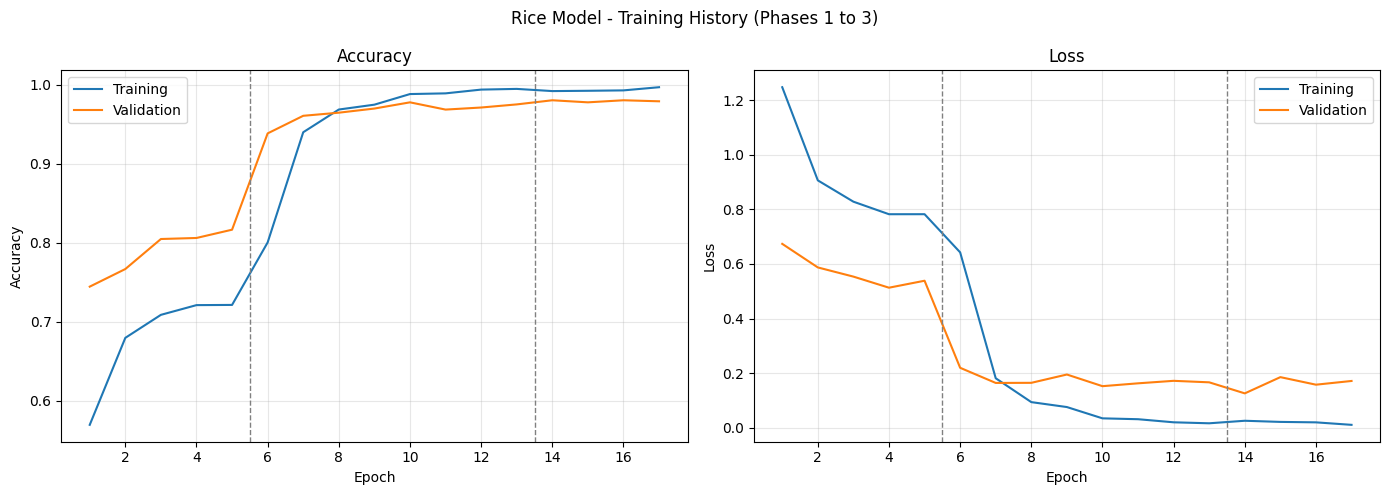

In [14]:
histories = [h1, h2, h3]

train_acc, val_acc, train_loss, val_loss = [], [], [], []
phase_ends = []
for h in histories:
    train_acc += h.history["accuracy"]
    val_acc += h.history["val_accuracy"]
    train_loss += h.history["loss"]
    val_loss += h.history["val_loss"]
    phase_ends.append(len(train_acc))

epochs_range = range(1, len(train_acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, train_acc, label="Training")
axes[0].plot(epochs_range, val_acc, label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")

axes[1].plot(epochs_range, train_loss, label="Training")
axes[1].plot(epochs_range, val_loss, label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")

for ax in axes:
    for end in phase_ends[:-1]:
        ax.axvline(end + 0.5, color="gray", linestyle="--", linewidth=1)
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Rice Model - Training History (Phases 1 to 3)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/rice_training_curves.png", dpi=150)
plt.show()

## 8. Evaluation

### 8.1 Validation set

The model is first evaluated on the validation set. Precision, recall and F1-score are reported for every class, followed by the confusion matrix. The validation set was also used to choose the best epoch, so the separate test set in section 8.3 gives a fairer final number.

In [15]:
y_true, y_pred = [], []
for imgs, lbls in val_ds_p:
    preds = model.predict(imgs, verbose=0)
    y_true.extend(np.argmax(lbls.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

val_accuracy = np.mean(y_true == y_pred)
print(f"Validation accuracy: {val_accuracy * 100:.2f}%  ({len(y_true)} images)\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

Validation accuracy: 98.03%  (763 images)

                       precision    recall  f1-score   support

Bacterial Leaf Blight     0.9789    0.9653    0.9720       144
           Brown Spot     0.9924    0.9774    0.9848       133
    Healthy Rice Leaf     1.0000    1.0000    1.0000       130
           Leaf Blast     0.9483    0.9735    0.9607       113
           Leaf scald     0.9690    0.9843    0.9766       127
        Sheath Blight     0.9913    0.9828    0.9870       116

             accuracy                         0.9803       763
            macro avg     0.9800    0.9805    0.9802       763
         weighted avg     0.9805    0.9803    0.9804       763



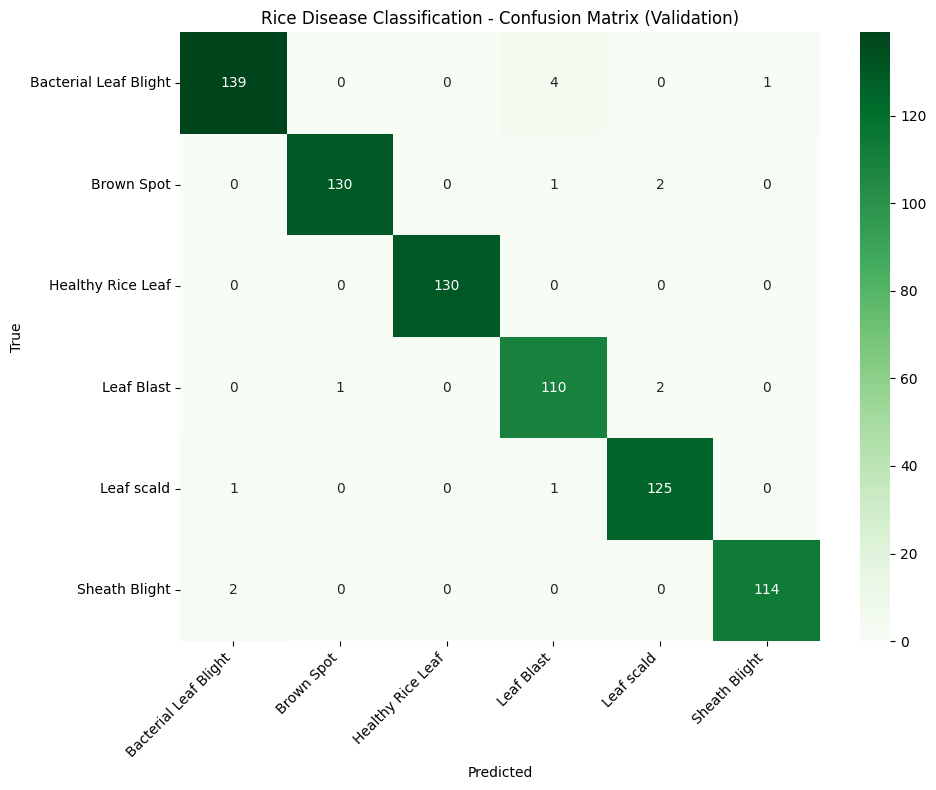

In [16]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Rice Disease Classification - Confusion Matrix (Validation)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/rice_confusion_matrix.png", dpi=150)
plt.show()

### 8.2 Sample predictions

A batch of validation images with the true label, the predicted label and the model's confidence. Green titles are correct predictions and red titles are mistakes.

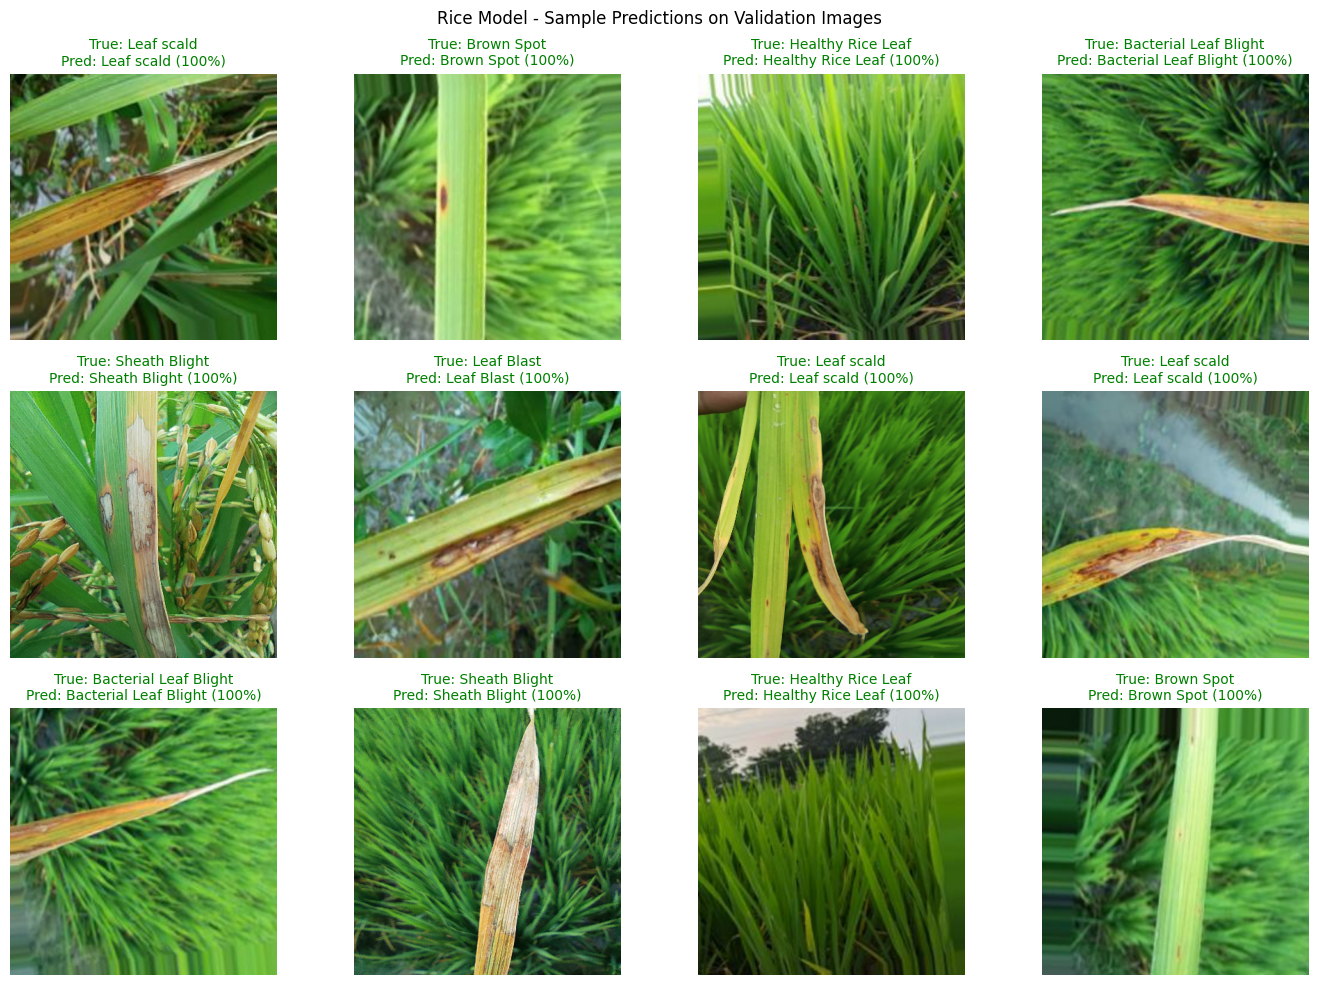

In [17]:
sample_images, sample_labels = next(iter(val_ds))
sample_probs = model.predict(preprocess_input(sample_images), verbose=0)

sample_true = np.argmax(sample_labels.numpy(), axis=1)
sample_pred = np.argmax(sample_probs, axis=1)

plt.figure(figsize=(14, 10))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(sample_images[i].numpy().astype("uint8"))
    plt.axis("off")

    confidence = sample_probs[i][sample_pred[i]] * 100
    correct = sample_true[i] == sample_pred[i]
    plt.title(f"True: {class_names[sample_true[i]]}\nPred: {class_names[sample_pred[i]]} ({confidence:.0f}%)",
              fontsize=10, color="green" if correct else "red")

plt.suptitle("Rice Model - Sample Predictions on Validation Images")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/rice_sample_predictions.png", dpi=150)
plt.show()

### 8.3 Test set

The dataset also has a separate test folder. These images were not used for training or for choosing the best epoch, so this is the fairest estimate of how the model works on new images. The test set is only used here, once.

In [18]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=False
)
assert test_ds.class_names == class_names, "test classes do not match train classes"

test_ds_p = test_ds.map(prep, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

y_true_test, y_pred_test = [], []
for imgs, lbls in test_ds_p:
    preds = model.predict(imgs, verbose=0)
    y_true_test.extend(np.argmax(lbls.numpy(), axis=1))
    y_pred_test.extend(np.argmax(preds, axis=1))

y_true_test = np.array(y_true_test)
y_pred_test = np.array(y_pred_test)

test_accuracy = np.mean(y_true_test == y_pred_test)
print(f"Test accuracy: {test_accuracy * 100:.2f}%  ({len(y_true_test)} images)\n")
print(classification_report(y_true_test, y_pred_test, target_names=class_names, digits=4))

Found 380 files belonging to 6 classes.


2026-10-27 07:05:30.443975: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 07:05:30.589020: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 07:05:31.491913: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 07:05:31.640135: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 07:05:33.103884: E external/local_xla/xla/stream_

Test accuracy: 97.89%  (380 images)

                       precision    recall  f1-score   support

Bacterial Leaf Blight     0.9400    1.0000    0.9691        47
           Brown Spot     0.9545    0.9692    0.9618        65
    Healthy Rice Leaf     1.0000    1.0000    1.0000        66
           Leaf Blast     0.9844    0.9403    0.9618        67
           Leaf scald     0.9861    0.9726    0.9793        73
        Sheath Blight     1.0000    1.0000    1.0000        62

             accuracy                         0.9789       380
            macro avg     0.9775    0.9804    0.9787       380
         weighted avg     0.9794    0.9789    0.9789       380



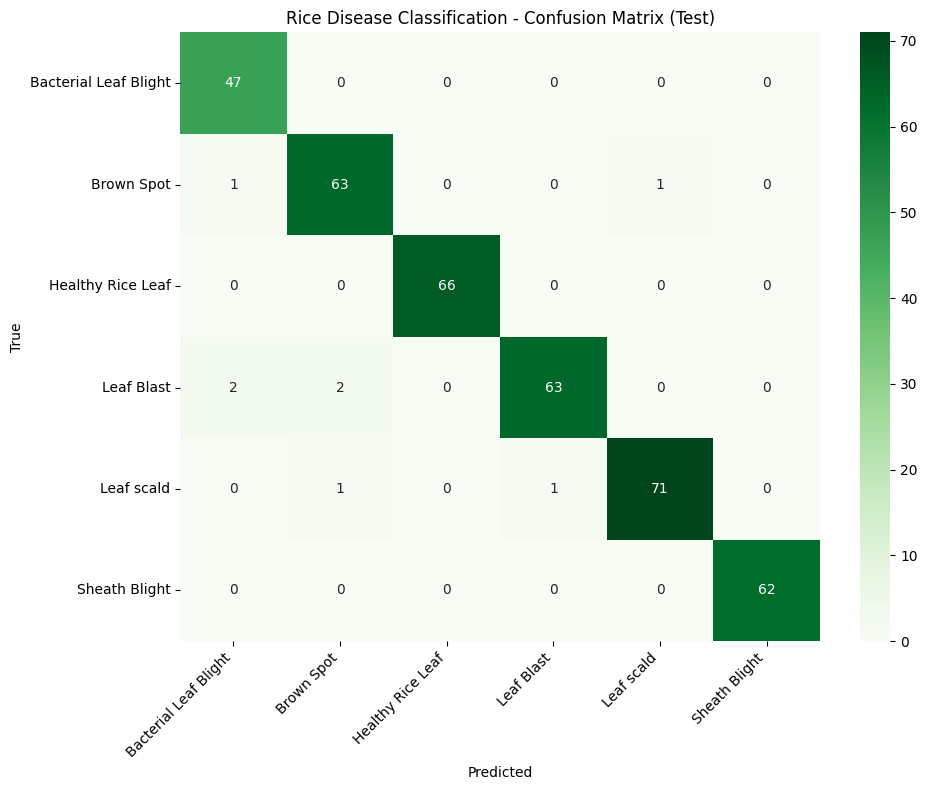

In [19]:
cm_test = confusion_matrix(y_true_test, y_pred_test)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Rice Disease Classification - Confusion Matrix (Test)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/rice_test_confusion_matrix.png", dpi=150)
plt.show()

## 9. Saving the Model

The final model is saved together with JSON files that the CropGuard AI backend needs:

- `rice_class_names.json`: the class labels in the same order as the model outputs, in the form `rice__<disease>`
- `rice_class_map.json`: maps each label to the crop name and the disease name
- `rice_class_names_raw.json`: the original folder names

Everything is then packed into one zip file.

In [20]:
model.save(f"{OUTPUT_DIR}/rice_final.keras")
size_mb = os.path.getsize(f"{OUTPUT_DIR}/rice_final.keras") / 1024 / 1024
print(f"Model saved ({size_mb:.1f} MB)")

Model saved (233.7 MB)


In [21]:
rice_class_map = {}
production_class_names = []

for cls in class_names:
    key = "rice__" + cls.lower().replace(" ", "_").replace("-", "_")
    production_class_names.append(key)
    rice_class_map[key] = {"crop": "Rice", "disease": cls}

with open(f"{OUTPUT_DIR}/rice_class_map.json", "w") as f:
    json.dump(rice_class_map, f, indent=2)
with open(f"{OUTPUT_DIR}/rice_class_names.json", "w") as f:
    json.dump(production_class_names, f, indent=2)
with open(f"{OUTPUT_DIR}/rice_class_names_raw.json", "w") as f:
    json.dump(class_names, f, indent=2)

print(json.dumps(rice_class_map, indent=2))

{
  "rice__bacterial_leaf_blight": {
    "crop": "Rice",
    "disease": "Bacterial Leaf Blight"
  },
  "rice__brown_spot": {
    "crop": "Rice",
    "disease": "Brown Spot"
  },
  "rice__healthy_rice_leaf": {
    "crop": "Rice",
    "disease": "Healthy Rice Leaf"
  },
  "rice__leaf_blast": {
    "crop": "Rice",
    "disease": "Leaf Blast"
  },
  "rice__leaf_scald": {
    "crop": "Rice",
    "disease": "Leaf scald"
  },
  "rice__sheath_blight": {
    "crop": "Rice",
    "disease": "Sheath Blight"
  }
}


In [22]:
files = [
    f"{OUTPUT_DIR}/rice_final.keras",
    f"{OUTPUT_DIR}/rice_best.keras",
    f"{OUTPUT_DIR}/rice_class_map.json",
    f"{OUTPUT_DIR}/rice_class_names.json",
    f"{OUTPUT_DIR}/rice_confusion_matrix.png",
    f"{OUTPUT_DIR}/rice_test_confusion_matrix.png",
    f"{OUTPUT_DIR}/rice_training_curves.png",
    f"{OUTPUT_DIR}/rice_sample_predictions.png",
]

zip_path = f"{OUTPUT_DIR}/rice_model_package.zip"
with zipfile.ZipFile(zip_path, "w") as zf:
    for f in files:
        if os.path.exists(f):
            zf.write(f, arcname=os.path.basename(f))
            print(f"added {os.path.basename(f)} ({os.path.getsize(f) / 1024 / 1024:.1f} MB)")
        else:
            print(f"missing: {f}")

print(f"\nPackage: {zip_path} ({os.path.getsize(zip_path) / 1024 / 1024:.1f} MB)")

added rice_final.keras (233.7 MB)
added rice_best.keras (233.7 MB)
added rice_class_map.json (0.0 MB)
added rice_class_names.json (0.0 MB)
added rice_confusion_matrix.png (0.1 MB)
added rice_test_confusion_matrix.png (0.1 MB)
added rice_training_curves.png (0.1 MB)
added rice_sample_predictions.png (3.1 MB)

Package: /kaggle/working/rice_model_package.zip (470.6 MB)


## 10. Summary and Limitations

**Summary**

- An EfficientNetV2S model was fine-tuned on rice leaf images from 6 classes using three training phases with decreasing learning rates.
- The original train, valid and test splits of the dataset were kept. The training split is already augmented, so no extra augmentation was added.
- The validation accuracy, per-class scores, confusion matrix and sample predictions are shown in section 8.1 and 8.2, and the held-out test result is in section 8.3.
- The saved model and class files are used in the CropGuard AI website and mobile app.

**Limitations**

- The validation set was used for early stopping and for choosing the best checkpoint, so the validation accuracy can be slightly higher than the true accuracy. The test set result is the fairer number.
- The training split contains augmented copies of images. If the dataset creator made augmented copies before splitting, some very similar images could appear in both training and validation or test, which would make the accuracy look better than it really is.
- The images may be different from photos that farmers take with their phones in the field (lighting, background, camera quality), so accuracy in real use can be lower.

**Future work**

- Test the model on a separate set of rice images collected from fields in Pakistan.
- Add more field images for the classes with the lowest scores.